# GCN models
- Visualise data and chose thresholds
- Prepare data
- Train classification model
- Predict and evaluate classification model
- Prepare data for regression model
- Train regression model
- Predict and evaluate regression model

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve
from sklearn.model_selection import train_test_split
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
plt.style.use('seaborn')
plt.rcParams['font.size'] = 18
from aux_functions import *

### 1. Import input data

Laget i `create_dataset.py`-fil.

In [2]:
df = pd.read_csv(r'./data/tot_cost_failure_scenarios_300322.csv')

###  2. Visualiser data

#### Histogram

Histogram has a gap around 1.3 and 1.8 p.u. We use the first gap for distinguising between low and high cost for the classification. Despite this gap, the classification model is expected to falsely classify some of the nearby points as low cost, so we train the regression model including some of those points.

In [3]:
class_thresh = 1.3
clamp_thresh = 1.45

df["Class"] = df.apply(lambda row: 0.0 if row["Total cost"] < class_thresh else 1.0, axis=1) # Should be just done with index rather than apply

In [4]:
high_cost_corrective = df.loc[df["Class"] == 1, 'Correction cost'].median()
high_cost_corrective # Used later as value for high cost scenarios

8.187550678436416

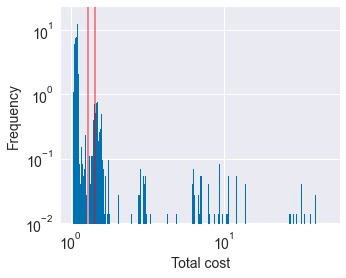

In [5]:
plt.style.use('seaborn-colorblind')
#plt.style.use('default')

fig, ax = plt.subplots(figsize=(5, 4))
#ax.set_ylim([0,1.1])
#ax.set_xlim([1,3])
ax.set_yscale('log')
ax.set_xscale('log')
ax = setfontsize(ax, 14)
df["Total cost"].plot.hist(bins=5000, ax=ax, density=True, xlabel='Total cost')
ax.set_xlabel('Total cost')
ax.axvline(class_thresh, color='red', alpha=0.5)
ax.axvline(clamp_thresh, color='red', alpha=0.5)
plt.savefig('./paper_figs/hist.png', bbox_inches='tight')

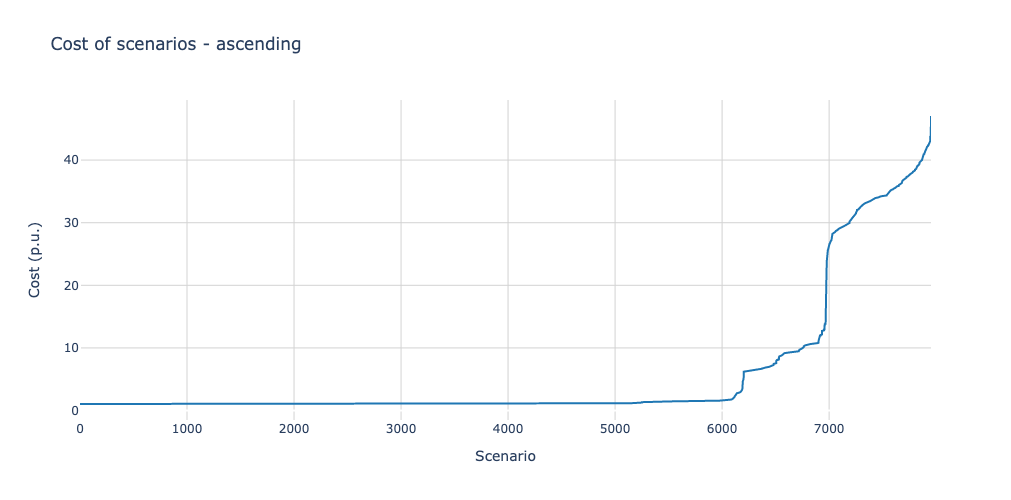

In [6]:
plot_df = df.sort_values(by=['Total cost'])
x_values = np.arange(plot_df.shape[0])

layout = go.Layout(
    title = f'Cost of scenarios - ascending',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['Total cost'], mode='lines', line=dict(color='#1F77B4'), name="True"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

#### Correlation plot

Check if any features correlate strongly with output of classification model

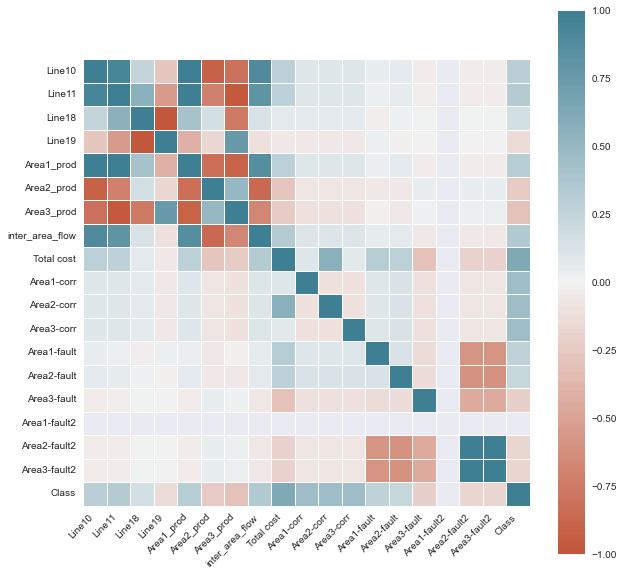

In [7]:
plot_var = ['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'inter_area_flow', 'fault', 'corr', 
          'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2', 'Class']


corr = df[plot_var].corr()
fig, ax = plt.subplots(figsize=(10,10))  
ax = sns.heatmap(
    corr, 
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True, linewidths=.5
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

## 4. Prepare data for classification
train_test_split splits data into train and test while also shuffling. Train 70%, validation 10%, test 20%
random_state chooses seed for shuffling which gives more consistency for our process.

Test dataset need to be large since this is what is used in regression model.

Splitting into train and test set while keeping all scenarios with the same prev_id in the same set.

In [8]:
prev_ids = df.prev_id.unique()
grouped = df.groupby(df.prev_id)

df_list = []
for prev_id in prev_ids:
    df_list.append(grouped.get_group(prev_id))


train_df_list, test_val_df_list = train_test_split(
    df_list, test_size=0.3, random_state=1
)
val_df_list, test_df_list = train_test_split(
    test_val_df_list, test_size=1 / 3, random_state=1
)

train_df = pd.concat(train_df_list)
val_df = pd.concat(val_df_list)
test_df = pd.concat(test_df_list)

### 4.Train classification model

In [9]:
is_tuning = False # True for hyper parameter optimization
%run -i "gcn_classification.py"

/Users/signer/packages/mambaforge-pypy3/envs/foo/lib/python3.9/site-packages/torch_geometric/deprecation.py:13: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

/Users/signer/packages/mambaforge-pypy3/envs/foo/lib/python3.9/site-packages/torch_geometric/deprecation.py:13: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

/Users/signer/packages/mambaforge-pypy3/envs/foo/lib/python3.9/site-packages/torch_geometric/deprecation.py:13: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead



Number of training graphs: 5567
Number of validation graphs: 1537
Number of test graphs: 849
Epoch: 001, Train Acc: 0.9766, Validation Acc: 0.9811
Epoch: 002, Train Acc: 0.9777, Validation Acc: 0.9837
Epoch: 003, Train Acc: 0.9770, Validation Acc: 0.9818
Epoch: 004, Train Acc: 0.9761, Validation Acc: 0.9798
Epoch: 005, Train Acc: 0.9775, Validation Acc: 0.9811
Epoch: 006, Train Acc: 0.9784, Validation Acc: 0.9844
Epoch: 007, Train Acc: 0.9826, Validation Acc: 0.9896
Epoch: 008, Train Acc: 0.9731, Validation Acc: 0.9772
Epoch: 009, Train Acc: 0.9761, Validation Acc: 0.9798
Epoch: 010, Train Acc: 0.9801, Validation Acc: 0.9824
Epoch: 011, Train Acc: 0.9736, Validation Acc: 0.9785
Epoch: 012, Train Acc: 0.9752, Validation Acc: 0.9798
Epoch: 013, Train Acc: 0.9801, Validation Acc: 0.9824
Epoch: 014, Train Acc: 0.9804, Validation Acc: 0.9837
Epoch: 015, Train Acc: 0.9804, Validation Acc: 0.9837
Epoch: 016, Train Acc: 0.9804, Validation Acc: 0.9837
Epoch: 017, Train Acc: 0.9801, Validation A

In [10]:
#output from hyperparameter run
#0.9908913467794405
#4
#The lowest total MSE value, 0.9908913, for the validation set was found with the following settings: 
#a learning rate of: 0.0009, a hidden channel nr of: 29.0
#a dropout rate of: 0.1000 and an epoch number of: 40.0

In [11]:
classification_model = model
classification_test_dataset = test_dataset

In [12]:
model

GCN(
  (conv1): GCNConv(5, 29)
  (conv2): GCNConv(29, 29)
  (conv3): GCNConv(29, 29)
  (lin): Linear(in_features=29, out_features=1, bias=True)
)

### 5. Output of classification model

#### Convergence plot

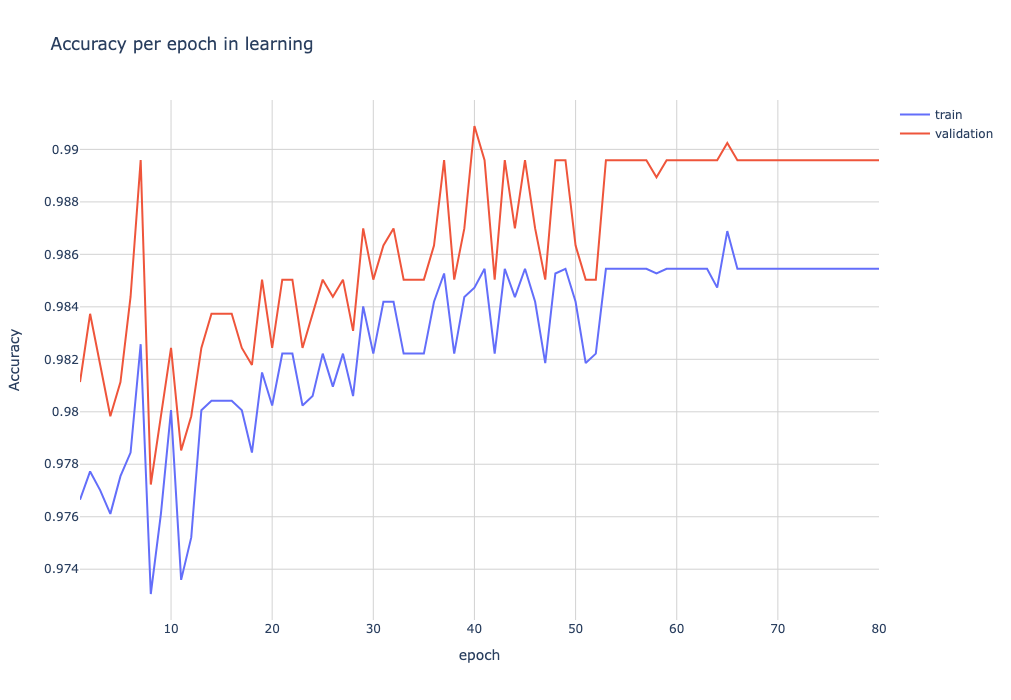

In [13]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"       # this sets its legend entry
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=val_list,
    name="validation"       # this sets its legend entry
))

fig.update_layout(
    title="Accuracy per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="MSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = 'Accuracy',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

### Classification results from test data

#### Precision-recall curve

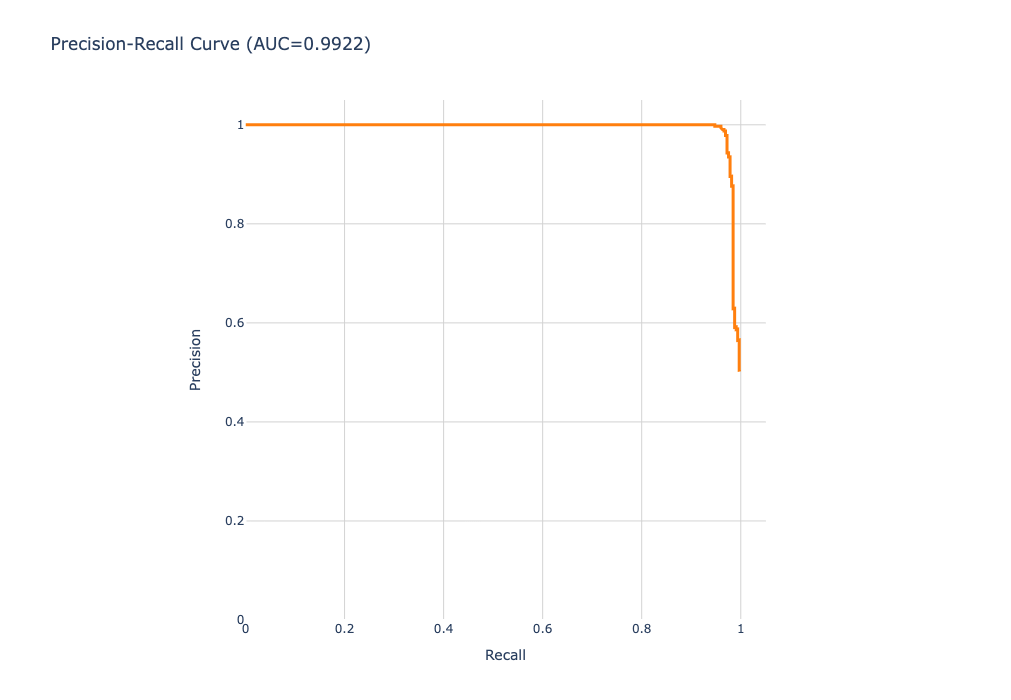

In [14]:
precision, recall, thresholds = precision_recall_curve(y_target, y_prob)

df_ = pd.DataFrame(data={"precision": precision, "recall": recall, "thresh":np.append(0, thresholds)})

layout = go.Layout(
    title = f'Precision-Recall Curve (AUC={auc(recall, precision):.4f})',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)
#fig.add_shape(
#    type='line', line=dict(dash='dash'),
#    x0=0, x1=1, y0=0.577, y1=0.577, name= "Baseline"
#)


fig.add_trace(go.Scatter(x=df_['recall'], y=df_['precision'], mode='lines', line=dict(color='#FF7F0E', width=3), name="curve",))

fig.update_layout(
    xaxis_title='Recall',
    yaxis_title='Precision',
    yaxis=dict(scaleanchor="x", scaleratio=1, range=[0,1.05]),
    xaxis=dict(constrain='domain', range=[0,1.05]),
    width=700, height=700
)
fig.show()
#fig, ax = plt.subplots()
#ax = setfontsize(ax, 18)
#ax.set_ylim([0, 1.1])
#ax.set_xlim([0, 1.1])
#ax.plot(df_['recall'], df_['precision'])
#ax.set_xlabel('Recall')
#ax.set_ylabel('Precision')

#plt.savefig('hist.png')

#### Threshold probability

The classification threshold probability is selected to provide the highest F2 value for the trained model.

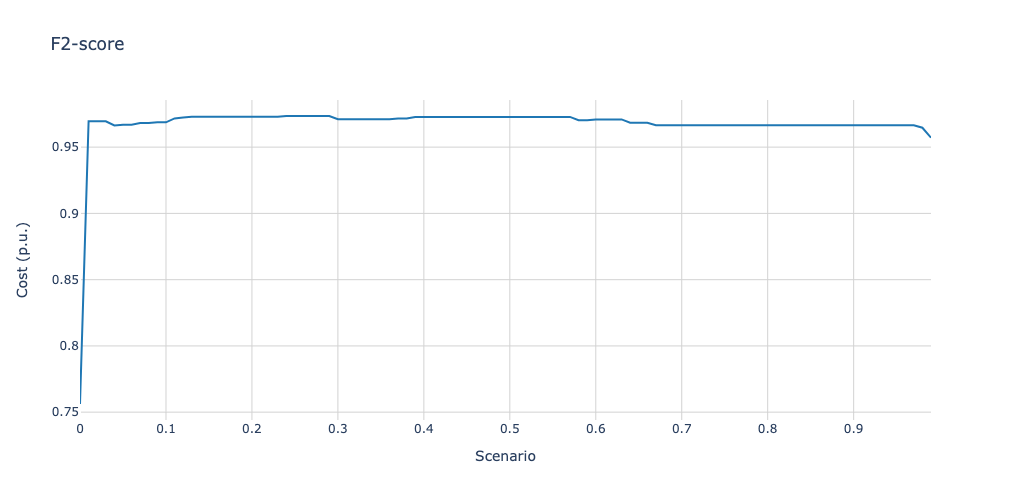

In [15]:
from sklearn.metrics import fbeta_score

t_prob = np.arange(0,1, 0.01)
f2_score = np.array([])

for thresh in t_prob:
    pred = np.array([1 if x > thresh else 0 for x in y_prob])
    f2_score = np.append(f2_score, fbeta_score(y_target, pred, beta=2))
    
layout = go.Layout(
    title = f'F2-score',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=t_prob, y=f2_score, mode='lines', line=dict(color='#1F77B4'), name="True"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

In [16]:
# Finn threshold som gir max f2-score
df_ = pd.DataFrame(data={"f2": f2_score, "thresh": t_prob})
th_p = df_['thresh'][df_['f2']==df_['f2'].max()].values[0]
th_p

0.24

In [17]:
# Bruk threshold for å klassifisere på nytt
y_pred_f2 = np.array([1 if x > th_p else 0 for x in y_prob])
y_pred = np.array([1 if x > 0.5 else 0 for x in y_prob])
acc = (y_target == y_pred_f2).sum()/len(y_target)
acc

0.9811542991755006

In [18]:
df_results['pred_f2'] = y_pred_f2
df_results['pred'] = y_pred

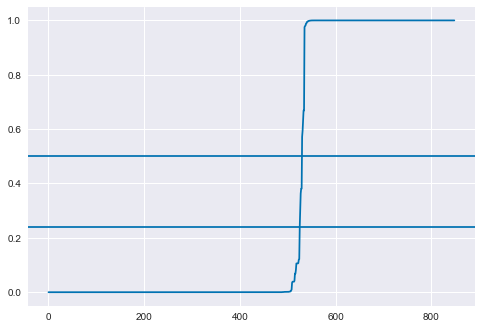

In [19]:
plt.plot(np.sort(y_prob))
plt.axhline(th_p)
plt.axhline(0.5)

#### Confusion matrix

In [20]:
tn, fp, fn, tp = confusion_matrix(y_target, y_pred_f2).ravel()
(tn, fp, fn, tp)

(517, 7, 9, 316)

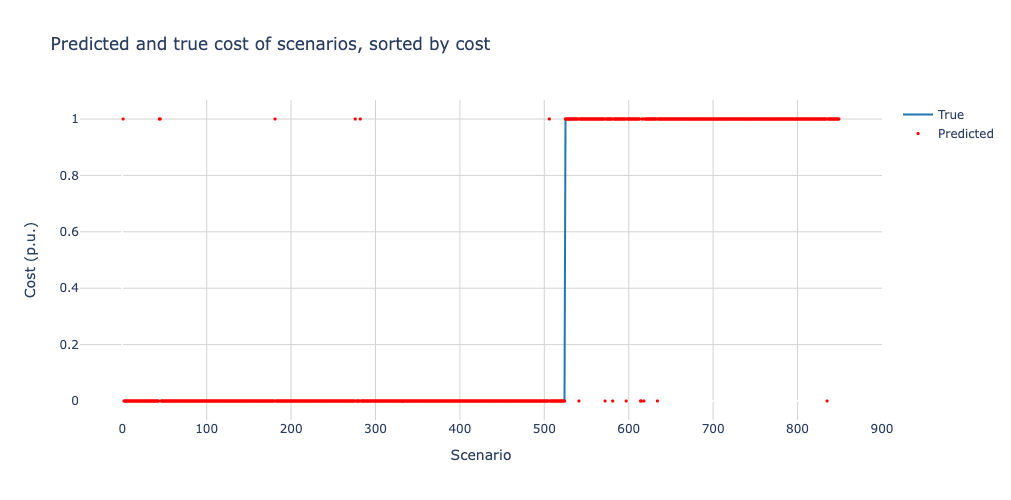

In [21]:
plot_df = df_results.sort_values(by=['target'])

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['pred_f2'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

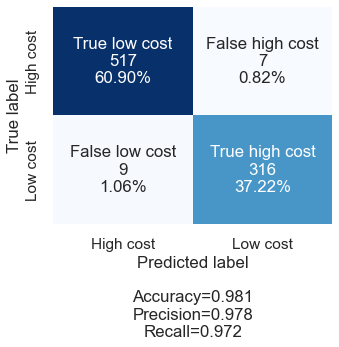

In [23]:
cf_matrix = confusion_matrix(df_results['target'], df_results['pred_f2'])

labels = ['True low cost','False high cost','False low cost','True high cost']
categories = ['High cost', 'Low cost']
make_confusion_matrix(cf_matrix, 
                      group_names=labels,
                      categories=categories, 
                      cmap='Blues',
                      title='',
                      cbar=False,
                      figsize=(5, 4))

plt.savefig("./paper_figs/confusion_matrix.png", bbox_inches='tight')

In [24]:
index_wrongclass = (df_results.target - df_results.pred_f2).abs() > 0
df_results.loc[index_wrongclass, ['Total cost', 'Dispatch costs', 'Correction cost']]

,Total cost,Dispatch costs,Correction cost
5787,1.066870,1.038699,0.028171
7520,1.068075,1.036421,0.031654
7526,10.261521,1.036421,9.225100
6653,1.334233,1.005794,0.328440
2807,11.408950,1.000731,10.408219
2405,1.070895,1.038779,0.032116
2406,1.183723,1.038779,0.144943
1232,1.160970,1.031049,0.129921
6236,1.066870,1.038699,0.028171
6990,7.123420,1.035534,6.087886


### 6. Export classification results to csv

In [25]:
# Bruk kun scenarier som er klassifisert som lavkostnads med ny terskel

#df = df_results[df_results['pred_f2']==0][['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load', 'inter_area_flow', 
#                  'fault', 'corr', 'Dispatch costs', 'CENS', 'Correction cost', 'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 
#                  'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2']].copy()


In [26]:
# Lagre resultatet i results-mappe slik at det kan brukes i Notebook_regression_multidim

#df.to_csv('results/input_regression_280322_threshold_1.3.csv', index = False)

In [27]:
# Lagre resultatet i for artikkel
#df_results.to_csv('results/results_classification_280322_threshold_1.3.csv', index = False)

### 7. Regression multidim

The regression model should be trained on the same training data as the classification model BUT only for values smaller than clamp_thresh (which is not a true clamp)

In [28]:
train_df_classifiction = train_df.copy()
val_df_classifiction = val_df.copy()
test_df_classifiction = test_df.copy()

train_df = train_df[train_df["Total cost"] < clamp_thresh].copy()
val_df = val_df[val_df["Total cost"] < clamp_thresh].copy()
test_df = test_df[test_df["Total cost"] < clamp_thresh].copy()

In [29]:
is_tuning = False # Satt til False så script ikke skal hyperparameteroptimalisere

%run -i "gcn_regression_multidim.py"

/Users/signer/packages/mambaforge-pypy3/envs/foo/lib/python3.9/site-packages/torch_geometric/deprecation.py:13: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

/Users/signer/packages/mambaforge-pypy3/envs/foo/lib/python3.9/site-packages/torch_geometric/deprecation.py:13: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

/Users/signer/packages/mambaforge-pypy3/envs/foo/lib/python3.9/site-packages/torch_geometric/deprecation.py:13: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead



Number of training graphs: 3842
Number of validation graphs: 1102
Number of test graphs: 555
Epoch: 001, Train Acc: 0.084032, Validation Acc: 0.069298
Epoch: 002, Train Acc: 0.081648, Validation Acc: 0.066778
Epoch: 003, Train Acc: 0.078644, Validation Acc: 0.064363
Epoch: 004, Train Acc: 0.077367, Validation Acc: 0.063272
Epoch: 005, Train Acc: 0.076694, Validation Acc: 0.062658
Epoch: 006, Train Acc: 0.076507, Validation Acc: 0.062451
Epoch: 007, Train Acc: 0.075832, Validation Acc: 0.061774
Epoch: 008, Train Acc: 0.076182, Validation Acc: 0.061981
Epoch: 009, Train Acc: 0.076513, Validation Acc: 0.062126
Epoch: 010, Train Acc: 0.075793, Validation Acc: 0.061482
Epoch: 011, Train Acc: 0.076163, Validation Acc: 0.061691
Epoch: 012, Train Acc: 0.075581, Validation Acc: 0.061140
Epoch: 013, Train Acc: 0.074556, Validation Acc: 0.060211
Epoch: 014, Train Acc: 0.074497, Validation Acc: 0.060112
Epoch: 015, Train Acc: 0.073452, Validation Acc: 0.059245
Epoch: 016, Train Acc: 0.073295, Vali

The lowest total MSE value, 0.0372971, for the test set was found with the following settings: 
a learning rate of: 0.0035, a hidden channel nr of: 41.0
a dropout rate of: 0.2500 and an epoch number of: 80.0

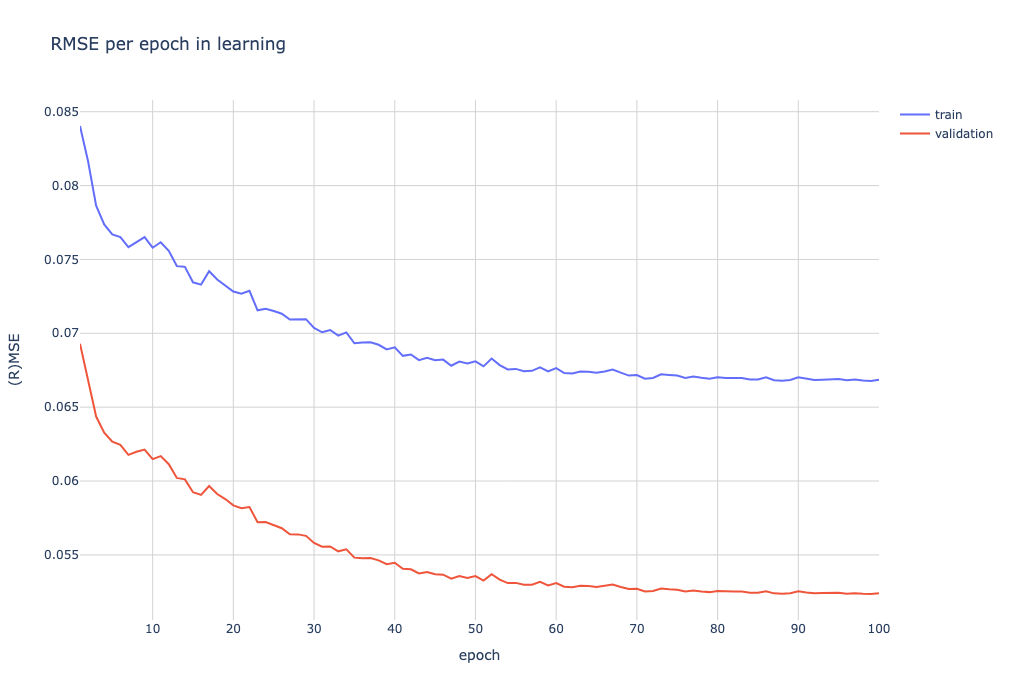

In [30]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=val_list,
    name="validation"
))

fig.update_layout(
    title="RMSE per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="RMSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = '(R)MSE',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

In [31]:
y_pred, y_target, scenarios = div.plotter(model, test_dataset)

y_pred2 = scale_y.inverse_transform(np.array(y_pred).reshape(-1, 2))
y_target2 = scale_y.inverse_transform(np.array(y_target).reshape(-1, 2))

df_results = test_df.copy()


df_results[["Dispatch_cost_target", "Correction_cost_target"]] = y_target2
df_results[["Dispatch_cost_pred", "Correction_cost_pred"]] = y_pred2
#df_results['tot_cost_pred'] = df_results["Dispatch_cost_pred"] + df_results["Correction_cost_pred"]

In [32]:
# Add regression results on dataframe with classification results
df_classification_results = test_df_classifiction
df_classification_results['pred_f2'] = y_pred_f2

y_pred_c, _, _ = div.plotter(model, classification_test_dataset)

y_pred2_c = scale_y.inverse_transform(np.array(y_pred_c).reshape(-1, 2))

df_classification_results[["Dispatch_cost_pred", "Correction_cost_pred"]] = y_pred2_c

#df_classification_results['tot_cost_pred'] = df_classification_results["Dispatch_cost_pred"] + df_classification_results["Correction_cost_pred"]
#y_pred, y_target, scenarios = div.plotter(model, test_dataset)

In [33]:
df_classification_results.columns

Index(['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod',
       'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load',
       'inter_area_flow', 'fault', 'corr', 'Dispatch costs', 'CENS',
       'FCR cost', 'Redispatch cost', 'SPS cost', 'Correction cost',
       'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault',
       'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2',
       'Area3-fault2', 'Class', 'inter_area_flow_scaled', 'Area1_prod_scaled',
       'Area2_prod_scaled', 'Area3_prod_scaled', 'pred_f2',
       'Dispatch_cost_pred', 'Correction_cost_pred'],
      dtype='object')

Dispatch cost rmse: 0.0001898229204210536
Corrective cost rmse: 0.003249373404116535


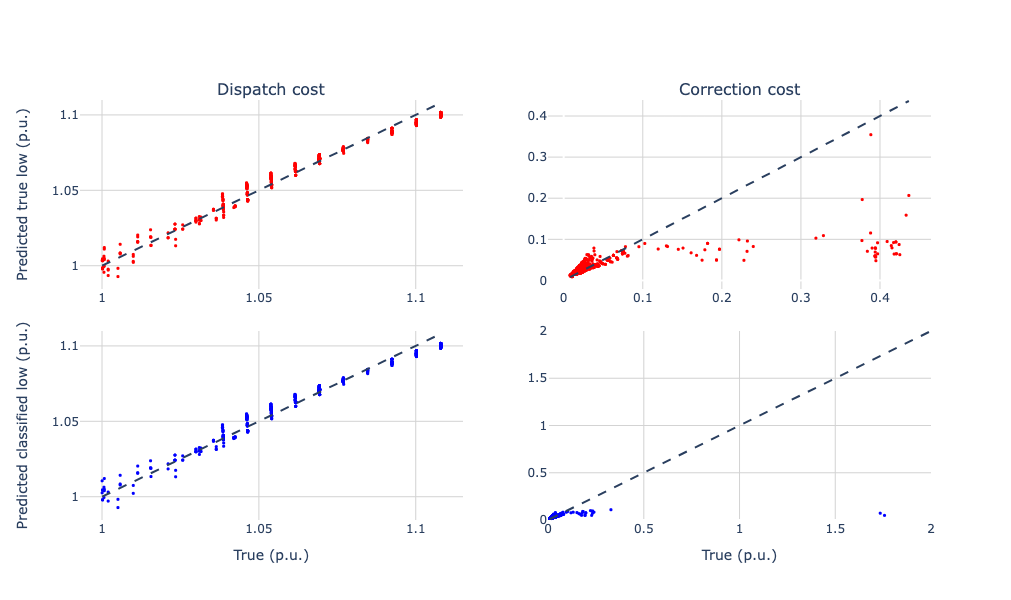

In [34]:
from plotly.subplots import make_subplots

thresh = class_thresh
plot_dfl = df_results
fig = make_subplots(rows=2, cols=2, subplot_titles=("Dispatch cost", "Correction cost"),
                   horizontal_spacing = 0.1, vertical_spacing = 0.1)

# Add scatters
x = plot_dfl['Dispatch_cost_target']
y = plot_dfl['Dispatch_cost_pred']
rmse = np.sqrt(np.sum((x-y)**2))/len(x)
print('Dispatch cost rmse:', rmse)
fig.add_scatter(x=x, y=y, 
                mode='markers', marker=dict(color='red', size=3), row=1, col=1)
fig.add_shape(type='line', line=dict(dash='dash'), name= "Baseline", row=1, col=1,
              x0=x.min(), x1=x.max(), 
              y0=x.min(), y1=x.max())


x = plot_dfl['Correction_cost_target']
y = plot_dfl['Correction_cost_pred']
rmse = np.sqrt(np.sum((x-y)**2))/len(x)
print('Corrective cost rmse:', rmse)

fig.add_scatter(x=x, y=y, 
                mode='markers', marker=dict(color='red', size=3), row=1, col=2)
fig.add_shape(type='line', line=dict(dash='dash'), name="Baseline", row=1, col=2,
              x0=x.min(), x1=x.max(), 
              y0=x.min(), y1=x.max())


index_lowcost = df_classification_results['pred_f2'] == 0
x = df_classification_results.loc[index_lowcost, 'Dispatch costs']
y = df_classification_results.loc[index_lowcost, 'Dispatch_cost_pred']
fig.add_scatter(x=x, y=y, 
                mode='markers', marker=dict(color='blue', size=3), row=2, col=1)

fig.add_shape(type='line', line=dict(dash='dash'), name= "Baseline", row=2, col=1,
              x0=x.min(), x1=x.max(), y0=x.min(), y1=x.max())

x = df_classification_results.loc[index_lowcost, 'Correction cost']
y = df_classification_results.loc[index_lowcost, 'Correction_cost_pred']
fig.add_scatter(x=x, y=y, 
                mode='markers', marker=dict(color='blue', size=3), row=2, col=2)

fig.add_shape(type='line', line=dict(dash='dash'), name= "Baseline", row=2, col=2,
              x0=x.min(), x1=x.max(), y0=x.min(), y1=x.max())






#fig.add_scatter(x=plot_dfl['Total cost'], y=plot_dfl['tot_cost_pred'], mode='markers', marker=dict(color='red', size=3), row=1, col=3)

#fig.add_shape(
#    type='line', line=dict(dash='dash'), name= "Baseline", row=1, col=3,
#    x0=plot_dfl['Total cost'].min(), x1=plot_dfl['Total cost'].max(), y0=plot_dfl['Total cost'].min(), y1=plot_dfl['Total cost'].max())

#fig.add_shape(
#    type='line', line=dict(dash='solid'), row=1, col=3,
#    x0=plot_dfl['Total cost'].min(), x1=thresh, y0=thresh, y1=thresh, name= "Baseline")

#fig.add_shape(
#    type='line', line=dict(dash='solid'), row=1, col=3,
#    x0=thresh, x1=thresh, y0=plot_dfl['tot_cost_pred'].min(), y1=thresh, name= "Baseline")

#index = df_classification_results['pred_f2'] == 0
#fig.add_scatter(x=df_classification_results.loc[index]['Total cost'], y=df_classification_results.loc[index]['tot_cost_pred'], mode='markers', marker=dict(color='blue', size=2), row=1, col=3)
#fig.add_scatter(x=[df_classification_results.loc[index]['Total cost'].max()], y=[df_classification_results.loc[index]['Total cost'].max()], mode='markers', marker=dict(color='white', size=1), row=1, col=3)

fig.update_xaxes(gridcolor='lightgrey')
fig.update_yaxes(gridcolor='lightgrey')
fig.update_xaxes(range=[0, 2], row=2, col=2)
fig.update_yaxes(range=[0, 2], row=2, col=2)
# Update axis properties
fig.update_xaxes(title_text="True (p.u.)", row=2, col=1)
fig.update_xaxes(title_text="True (p.u.)", row=2, col=2)
fig.update_yaxes(title_text="Predicted true low (p.u.)", row=1, col=1)
fig.update_yaxes(title_text="Predicted classified low (p.u.)", row=2, col=1)
fig.update_layout(showlegend=False)



fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=600, height=600, 
#    yaxis_title='Predicted (p.u.)',
#    xaxis_title='True (p.u.)'
)
fig.show()
fig.write_image("./paper_figs/true_vs_pred.png")
#plt.savefig('./paper_figs/true_vs_pred.png')

In [35]:
# Model performance



In [36]:
## Compute cost

In [37]:
# Only look at instances already classified as low cost
index_lowcost = df_classification_results['pred_f2'] == 0
# List prev ids for which at least one scenario is classified as high and one as low cost?
#index_lowcost = df_classification_results['pred_f2'] == 0
#index_highcost = df_classification_results['pred_f2'] == 1
#high_low = np.intersect1d(df_classification_results.loc[index_lowcost, 'prev_id'].values, 
#                           df_classification_results.loc[index_highcost, 'prev_id'].values)

# Include all corrective for preventive with one low-cost corrective
#index_previd_low = df_classification_results.prev_id.isin(df_classification_results[df_classification_results['pred_f2'] == 0].prev_id.unique())
#index_lowcost = df_classification_results.prev_id.isin(df_classification_results[df_classification_results['pred_f2'] == 0].prev_id.unique())

#df_rl = df_classification_results.loc[index_lowcost].copy()

df_rl = df_classification_results.copy()
df_rl.loc[~index_lowcost, 'Correction_cost_pred'] = high_cost_corrective  # class_thresh # - df_rl.loc[~index_lowcost, 'Dispatch_cost_pred']
# Not sure exactly what is going on here
#df_rl['d_acc'] = (df_rl['Dispatch costs'] - df_rl['Dispatch_cost_pred'])**2
#df_rl['c_acc'] = (df_rl['Correction cost'] - df_rl['Correction_cost_pred'])**2

#nrmse_d = (df_rl['d_acc'].mean())**0.5/df_rl['Dispatch costs'].mean()
#nrmse_c = (df_rl['c_acc'].mean())*0.5/df_rl['Correction cost'].mean()
#100*(nrmse_d + nrmse_c)/2

In [38]:
#Keep lowest cost per given prv and fault
df_rl["prev_id, fault"] = df_rl[['prev_id', 'fault']].agg('-'.join, axis=1)

# To make plot for low cost and set max_ to be threshold value

# First find out how many failure scenarios per prev has in dataset

agg = {
    'fault': list,
    'corr': list,
}

df_fault = df_rl.groupby("prev_id").agg(agg)
df_fault["fault unique"] = df_fault["fault"].apply(lambda row: list(dict.fromkeys(row)))
df_fault.head()

,fault,corr,fault unique
prev_id,,,
p1000,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1035,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1041,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1042,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1050,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"


In [39]:
# Derive the number of faults classified as high cost for each preventive id (denoted by missing)

df_fault["num fault missing"] = df_fault["fault unique"].apply(lambda row: 4 - len(row))
df_fault[df_fault["num fault missing"] != 0].head()
print(len(df_fault[df_fault["num fault missing"] != 0]))

0


In [40]:
df_rl.set_index('prev_id', inplace=True)

# Add to dataframe
df_rl = df_rl.join(df_fault[['num fault missing']])

In [41]:
# Sort values in ascending order so value kept is corrective measure with lowest cost
df_sort = df_rl.sort_values(['prev_id, fault', 'Total cost'])
df_d = df_sort.drop_duplicates('prev_id, fault', keep='first')
df_d.head()

,Line10,Line11,Line18,Line19,Area1_prod,Area2_prod,Area3_prod,Area1_load,Area2_load,Area3_load,...,Class,inter_area_flow_scaled,Area1_prod_scaled,Area2_prod_scaled,Area3_prod_scaled,pred_f2,Dispatch_cost_pred,Correction_cost_pred,"prev_id, fault",num fault missing
prev_id,,,,,,,,,,,,,,,,,,,,,
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.070782,0.023409,p1000-fault_L10,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.071811,0.035642,p1000-fault_L11,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.070502,0.023178,p1000-fault_L18,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.069389,0.023666,p1000-fault_L19,0
p1035,43.065264,131.722460,70.927479,-63.584629,407.721211,193.943950,501.962118,129.41124,102.497107,768.196686,...,0.0,0.071908,0.686298,0.326116,0.845079,0,1.058422,0.030884,p1035-fault_L10,0


In [42]:
# Per scenario: mean dispatch cost and sum correction costs

aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'Line10': 'mean',
    'fault': list,
    'corr': list,
    'Dispatch costs': 'mean', # Mean of dispatch costs
    'Dispatch_cost_pred': 'mean',
    'Correction cost': 'sum', # Sum up correction costs
    'Correction_cost_pred': 'sum',
    'CENS': 'mean',
    'num fault missing': 'mean'
}

# Use formula given earlier to find cost per preventive strategy

df_prev = df_d.groupby("prev_id").agg(aggregations)
df_prev.head()

,inter_area_flow,Line11,Line10,fault,corr,Dispatch costs,Dispatch_cost_pred,Correction cost,Correction_cost_pred,CENS,num fault missing
prev_id,,,,,,,,,,,
p1000,1.349568,111.457467,1.349568,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069159,1.070621,0.109234,0.105896,0.0,0.0
p1035,43.065264,131.722460,43.065264,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.053963,1.058004,0.123169,0.132203,0.0,0.0
p1041,18.548246,111.457467,18.548246,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069270,1.072362,0.099762,0.095764,0.0,0.0
p1042,37.533339,111.457467,37.533339,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069392,1.070210,0.089178,0.098962,0.0,0.0
p1050,0.385843,81.059977,0.385843,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.092439,1.088684,0.062704,0.072175,0.0,0.0


In [43]:
df_states = pd.read_csv(r'./data/state_prev_300322.csv')
for prev_id in df_prev.index:
    df_prev.loc[prev_id, 'state'] = df_states[df_states['Unnamed: 0'] == prev_id].state.values

In [44]:
# Find prev ids that have one or more scenarios with CENS or saved by SPS

#df_prev["corr_unique"] = df_prev["corr"].apply(lambda x: list(dict.fromkeys(x)))

In [45]:
#def classify_prev(row):
#    if row["CENS"] > 0:
#        return "Not N-1 safe"
#    else:
#        if len(row["corr_unique"])==1 and row["corr_unique"][0] == 'fault':
#            return "N-1 safe"
#        else:
#            return "Saved by SPS"
#df_prev["corr3"] = df_prev.apply(classify_prev, axis=1)  
#df_prev[df_prev["corr3"] != "N-1 safe"]

In [46]:
#Calculate total expected cost given failure_rate
failure_rate = 0.01
df_prev["total_cost_target"] =  df_prev["Dispatch costs"] + failure_rate*df_prev["Correction cost"]
df_prev["total_cost_pred"] =  df_prev["Dispatch_cost_pred"] + failure_rate*df_prev["Correction_cost_pred"]

In [47]:
df_prev["total_cost_target"].max()

1.378178419362932

In [48]:
aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'Line10': 'mean',

    'fault': list,
    'corr': list,
    'Dispatch costs': 'mean', # Mean of dispatch costs
    'Dispatch_cost_pred': 'mean',
    'Correction cost': 'sum', # Sum up correction costs
    'Correction_cost_pred': 'sum',
    'CENS': 'mean',
}


df_prev_classification = df_classification_results.groupby("prev_id").agg(aggregations)
for prev_id in df_prev_classification.index:
    df_prev_classification.loc[prev_id, 'state'] = df_states[df_states['Unnamed: 0'] == prev_id].state.values
    
df_prev_classification["total_cost_target"] =  df_prev_classification["Dispatch costs"] + failure_rate*df_prev_classification["Correction cost"]

N-1 safe 117
N-1 safe 117
Saved by SPS 19
Saved by SPS 19
Not N-1 safe 5
Not N-1 safe 5


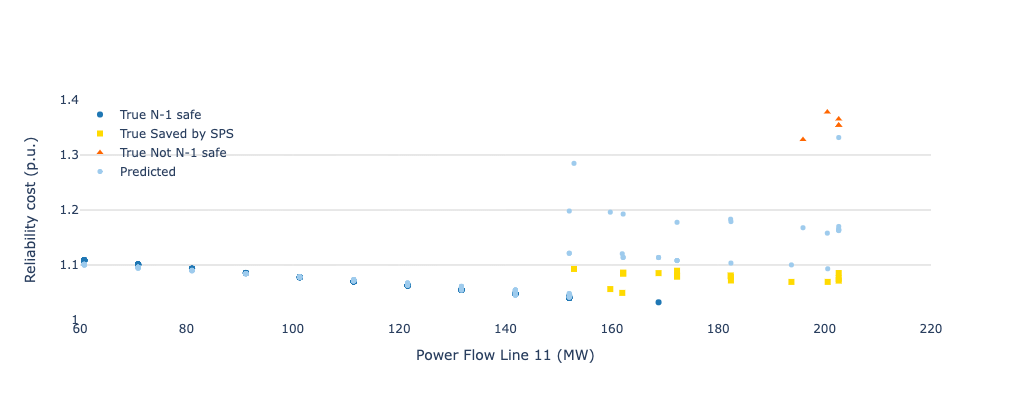

In [49]:
plot_df = df_prev

# subplot setup
fig = make_subplots(rows=1, cols=1)#, vertical_spacing = 0.04)
#fig.update_layout(title = 'Expected cost of preventive strategies given ρ={} and thr={} p.u.'.format(failure_rate, class_thresh))

groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]
colors = ["#1F77B4","#FFDA00", "#FF6600"]
symbols = ["circle", "square", "triangle-up"]

for index, group in enumerate(groups):
    group_index = plot_df['state'] == group
    print(group, len(plot_df.loc[group_index]))
    if len(plot_df.loc[group_index])>0:
        group_df = plot_df.loc[group_index]
        fig.add_trace(go.Scatter(x=group_df["Line11"], y=group_df['total_cost_target'], 
                             marker=dict(color=colors[index], size=6, symbol=symbols[index]), mode='markers', 
                             name='True {}'.format(group), hovertemplate = ('Prev id: ' + group_df.index)), row=1, col=1)
#        fig.add_trace(go.Scatter(x=group_df["Line11"], y=group_df['total_cost_target'], 
#                             marker=dict(color=colors[index], size=6, symbol=symbols[index]), mode='markers', 
#                             name='True {}'.format(group), hovertemplate = ('Prev id: ' + group_df.index)), row=2, col=1)

#        if group == 'Saved by SPS':
#            display(group_df)
    group_index = df_prev_classification['state'] == group
    print(group, len(df_prev_classification.loc[group_index]))        
        
    
fig.add_trace(go.Scatter(x=plot_df["Line11"], y=plot_df['total_cost_pred'], mode='markers', 
                         marker=dict(color='#9ecbed', size=5), name="Predicted", 
                         hovertemplate = ('Prev id :' + plot_df.index)), row=1, col=1)


# Some aesthetical adjustments to layout
fig.update_yaxes(range=[1, 1.4], row=1, col=1, gridcolor='lightgrey')
fig.update_xaxes(range=[60, 220], row=1, col=1)#, gridcolor='lightgrey')
#fig['layout']['yaxis1'].update(domain=[0, 1])

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    xaxis_title='Power Flow Line 11 (MW)',
    yaxis_title='Reliability cost (p.u.)',
    width=600, height=400, 
    legend=dict(yanchor="top", y=1, xanchor="left", x=0))

fig.show()
fig.write_image("./paper_figs/cost_vs_line11.png")


N-1 safe 117
N-1 safe 117
Saved by SPS 19
Saved by SPS 19
Not N-1 safe 5
Not N-1 safe 5


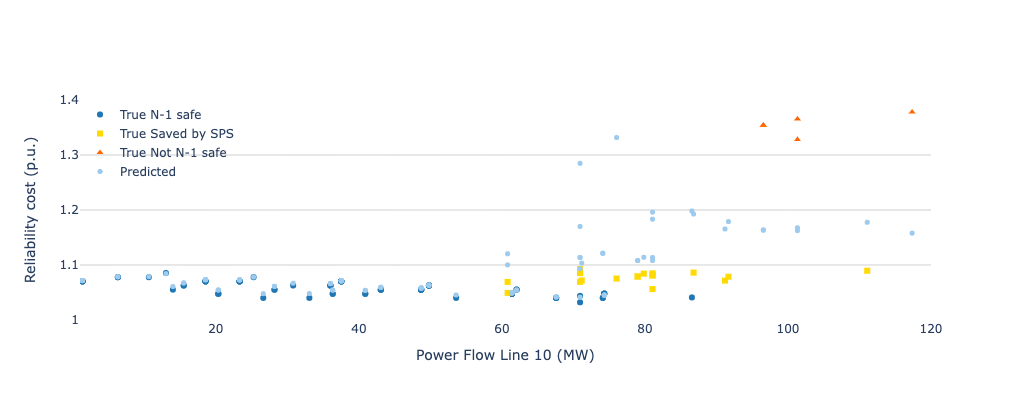

In [55]:
plot_df = df_prev

# subplot setup
fig = make_subplots(rows=1, cols=1)#, vertical_spacing = 0.04)
#fig.update_layout(title = 'Expected cost of preventive strategies given ρ={} and thr={} p.u.'.format(failure_rate, class_thresh))

groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]
colors = ["#1F77B4","#FFDA00", "#FF6600"]
symbols = ["circle", "square", "triangle-up"]

for index, group in enumerate(groups):
    group_index = plot_df['state'] == group
    print(group, len(plot_df.loc[group_index]))
    if len(plot_df.loc[group_index])>0:
        group_df = plot_df.loc[group_index]
        fig.add_trace(go.Scatter(x=group_df["Line10"], y=group_df['total_cost_target'], 
                             marker=dict(color=colors[index], size=6, symbol=symbols[index]), mode='markers', 
                             name='True {}'.format(group), hovertemplate = ('Prev id: ' + group_df.index)), row=1, col=1)

#        if group == 'Saved by SPS':
#            display(group_df)
    group_index = df_prev_classification['state'] == group
    print(group, len(df_prev_classification.loc[group_index]))        
        
    
fig.add_trace(go.Scatter(x=plot_df["Line10"], y=plot_df['total_cost_pred'], mode='markers', 
                         marker=dict(color='#9ecbed', size=5), name="Predicted", 
                         hovertemplate = ('Prev id :' + plot_df.index)), row=1, col=1)


# Some aesthetical adjustments to layout
fig.update_yaxes(range=[1, 1.4], row=1, col=1, gridcolor='lightgrey')
fig.update_xaxes(range=[1, 120], row=1, col=1)#, gridcolor='lightgrey')
#fig['layout']['yaxis1'].update(domain=[0, 1])

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    xaxis_title='Power Flow Line 10 (MW)',
    yaxis_title='Reliability cost (p.u.)',
    width=600, height=400, 
    legend=dict(yanchor="top", y=1, xanchor="left", x=0))

fig.show()
fig.write_image("./paper_figs/cost_vs_line10.png")

N-1 safe 117
N-1 safe 117
Saved by SPS 19
Saved by SPS 19
Not N-1 safe 5
Not N-1 safe 5


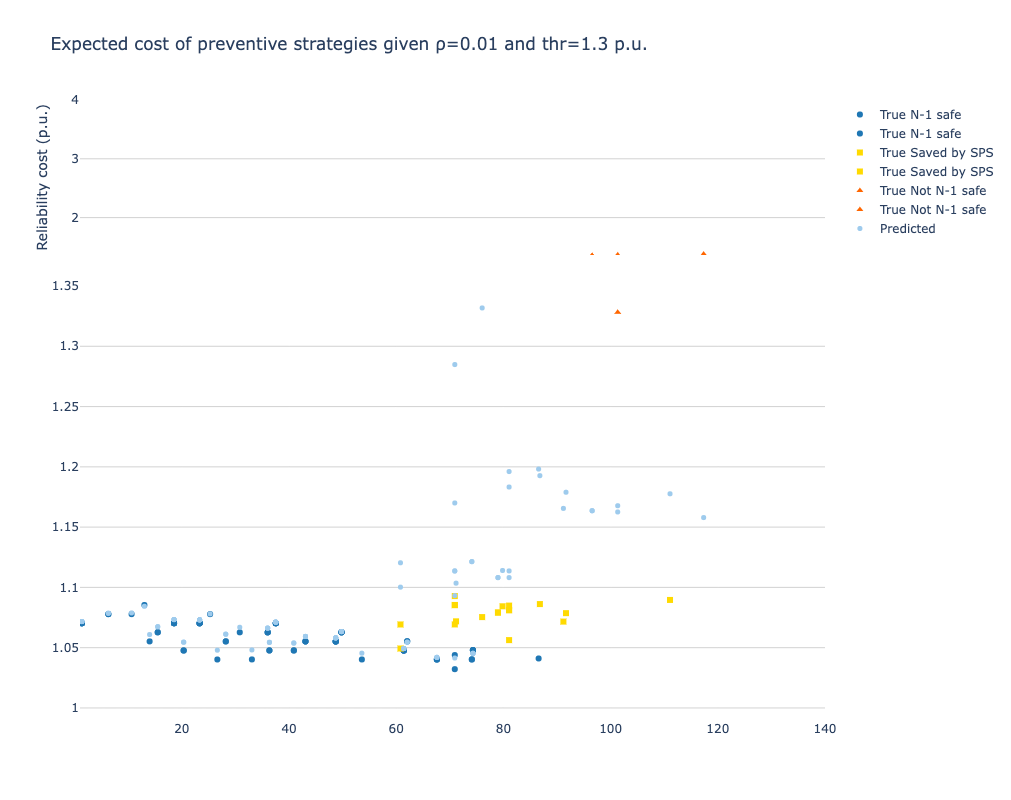

In [51]:
plot_df = df_prev#[df_prev["num fault missing"] == 0].copy()  ##?

# colors and cut-offs

#cut_interval = [1.15, 1.35]


# subplot setup
fig = make_subplots(rows=2, cols=1, vertical_spacing = 0.04)
fig.update_layout(title = 'Expected cost of preventive strategies given ρ={} and thr={} p.u.'.format(failure_rate, class_thresh))


# Make df for high cost

#plot_df4 = df_prev[df_prev["total_cost_target"] > 1.2].copy()
#plot_df5 = plot_df[plot_df["total_cost_target"] < 1.2].copy()
groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]

colors = ["#1F77B4","#FFDA00", "#FF6600"]
symbols = ["circle", "square", "triangle-up"]

for index, group in enumerate(groups):
#    new_df = plot_df5[plot_df5['corr3'] == group]
    group_index = plot_df['state'] == group
    print(group, len(plot_df.loc[group_index]))
    if len(plot_df.loc[group_index])>0:
        group_df = plot_df.loc[group_index]
        fig.add_trace(go.Scatter(x=group_df["Line10"], y=group_df['total_cost_target'], 
                             marker=dict(color=colors[index], size=6, symbol=symbols[index]), mode='markers', 
                             name='True {}'.format(group), hovertemplate = ('Prev id: ' + group_df.index)), row=1, col=1)
        fig.add_trace(go.Scatter(x=group_df["Line10"], y=group_df['total_cost_target'], 
                             marker=dict(color=colors[index], size=6, symbol=symbols[index]), mode='markers', 
                             name='True {}'.format(group), hovertemplate = ('Prev id: ' + group_df.index)), row=2, col=1)

    group_index = df_prev_classification['state'] == group
    print(group, len(df_prev_classification.loc[group_index]))
#    if len(df_prev_classification.loc[group_index])>0:
#        fig.add_trace(go.Scatter(x=df_prev_classification.loc[group_index]["Line11"], y=df_prev_classification.loc[group_index]['total_cost_target'],
#                         mode='markers', marker=dict(color=colors[index], size=6, symbol='square-open'), name="all", 
#                         hovertemplate = ('Prev id :' + plot_df.index)), row=1, col=1)
#        fig.add_trace(go.Scatter(x=df_prev_classification.loc[group_index]["Line11"], y=df_prev_classification.loc[group_index]['total_cost_target'],
#                         mode='markers', marker=dict(color=colors[index], size=6, symbol='square-open'), name="all", 
#                         hovertemplate = ('Prev id :' + plot_df.index)), row=2, col=1)
        
        
    
fig.add_trace(go.Scatter(x=plot_df["Line10"], y=plot_df['total_cost_pred'], mode='markers', 
                         marker=dict(color='#9ecbed', size=5), name="Predicted", 
                         hovertemplate = ('Prev id :' + plot_df.index)), row=2, col=1)

    
#fig.add_trace(go.Scatter(x=plot_df4["Line11"], y=plot_df4['total_cost_target'], 
#                         mode='markers', marker=dict(color=colors[2], size=5), name="True Not N-1 safe", 
#                         hovertemplate = ('Prev id: ' + plot_df4.index)), row=1, col=1)


#fig.add_trace(go.Scatter(x=df_prev_classification["Line11"], y=df_prev_classification['total_cost_target'],
#                         mode='markers', marker=dict(color='green', size=6, symbol='square-open'), name="all", 
#                         hovertemplate = ('Prev id :' + plot_df.index)), row=1, col=1)
#fig.add_trace(go.Scatter(x=df_prev_classification["Line11"], y=df_prev_classification['total_cost_target'],
#                         mode='markers', marker=dict(color='green', size=6, symbol='square-open'), name="all", 
#                         hovertemplate = ('Prev id :' + plot_df.index)), row=2, col=1)

split_plot = 1.35

# Create own dataframe for prev_ids without all failure scenarios
plot_df_high = df_prev[df_prev["num fault missing"] > 0].copy()
#plot_df_high['total_cost_target'] = 1.5*split_plot
fig.add_trace(go.Scatter(x=plot_df_high["Line10"], y=plot_df_high['total_cost_target'], mode='markers', marker=dict(color='#6a6a6a', size=8, symbol='circle-open'), 
                         name="1 or more contingency scenarios classified as high cost", hovertemplate = ('Prev id: ' + plot_df_high.index)), row=2, col=1)
fig.add_trace(go.Scatter(x=plot_df_high["Line10"], y=plot_df_high['total_cost_target'], mode='markers', marker=dict(color='#6a6a6a', size=8, symbol='circle-open'), 
                         name="1 or more contingency scenarios classified as high cost", hovertemplate = ('Prev id: ' + plot_df_high.index)), row=1, col=1)

# Add shaded area

#fig.add_vrect(x0=plot_df_high["Line11"].min(), x1=plot_df_high["Line11"].max(), fillcolor="red", opacity=0.25, line_width=0)



# Some aesthetical adjustments to layout
#fig.update_yaxes(range=[0.9*new_df['total_cost_target'].min(), 1.1*new_df['total_cost_target'].max()], row=2, col=1, gridcolor='lightgrey')
#fig.update_yaxes(range=[0.9*plot_df4['total_cost_target'].min(), 1.1*plot_df4['total_cost_target'].max()], row=1, col=1, gridcolor='lightgrey')
fig.update_yaxes(range=[0.99, split_plot], row=2, col=1, gridcolor='lightgrey')
fig.update_yaxes(range=[1.01*split_plot, 4], row=1, col=1, gridcolor='lightgrey')
fig.update_xaxes(range=[1, 140], visible=True, row=2, col=1)#, gridcolor='lightgrey')
fig.update_xaxes(range=[1, 140], visible=False, row=1, col=1)#, gridcolor='lightgrey')
fig['layout']['yaxis1'].update(domain=[0.75, 1])
fig['layout']['yaxis2'].update(domain=[0, 0.7])

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    xaxis_title='Power Flow Line 11 (MW)',
    yaxis_title='Reliability cost (p.u.)',
    width=1500, height=800
)

fig.show()

In [52]:
plot_df

,inter_area_flow,Line11,Line10,fault,corr,Dispatch costs,Dispatch_cost_pred,Correction cost,Correction_cost_pred,CENS,num fault missing,state,total_cost_target,total_cost_pred
prev_id,,,,,,,,,,,,,,
p1000,1.349568,111.457467,1.349568,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069159,1.070621,0.109234,0.105896,0.0,0.0,[N-1 safe],1.070251,1.071680
p1035,43.065264,131.722460,43.065264,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.053963,1.058004,0.123169,0.132203,0.0,0.0,N-1 safe,1.055195,1.059326
p1041,18.548246,111.457467,18.548246,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069270,1.072362,0.099762,0.095764,0.0,0.0,N-1 safe,1.070267,1.073319
p1042,37.533339,111.457467,37.533339,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069392,1.070210,0.089178,0.098962,0.0,0.0,N-1 safe,1.070284,1.071199
p1050,0.385843,81.059977,0.385843,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.092439,1.088684,0.062704,0.072175,0.0,0.0,N-1 safe,1.093066,1.089405
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
p950,25.202490,60.794982,-25.202490,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.107996,1.099455,0.053373,0.065444,0.0,0.0,N-1 safe,1.108529,1.100109
p961,13.988024,131.722460,13.988024,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.053776,1.059565,0.142332,0.131946,0.0,0.0,N-1 safe,1.055199,1.060885
p963,43.065264,131.722460,43.065264,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.053963,1.058004,0.123169,0.132203,0.0,0.0,N-1 safe,1.055195,1.059326


In [53]:
plot_df = df_prev[df_prev["num fault missing"] == 0].copy()  ##?

# colors and cut-offs

# subplot setup
fig = make_subplots(rows=1, cols=1, vertical_spacing = 0.04)
fig.update_layout(title = 'Expected cost of preventive strategies given ρ={} and thr={} p.u.'.format(failure_rate, class_thresh))


# Make df for high cost

plot_df4 = df_prev[df_prev["total_cost_target"] > 1.2].copy()

plot_df5 = plot_df[plot_df["total_cost_target"] < 1.2].copy()
groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]
colors = ["#1F77B4","#FFDA00", "#FF6600"]

for index, group in enumerate(groups):
    new_df = plot_df5[plot_df5['corr3'] == group]
    fig.add_trace(go.Scatter(x=new_df["Line11"], y=new_df['total_cost_target'], 
                             marker=dict(color=colors[index], size=5), mode='markers', 
                             name='True {}'.format(group), hovertemplate = ('Prev id: ' + new_df.index)), row=1, col=1)


fig.add_trace(go.Scatter(x=plot_df["Line11"], y=plot_df['total_cost_pred'], mode='markers', 
                         marker=dict(color='#9ecbed', size=5), name="Predicted", 
                         hovertemplate = ('Prev id :' + plot_df.index)), row=1, col=1)

    
fig.add_trace(go.Scatter(x=plot_df4["Line11"], y=plot_df4['total_cost_target'], 
                         mode='markers', marker=dict(color=colors[2], size=5), name="True Not N-1 safe", 
                         hovertemplate = ('Prev id: ' + plot_df4.index)), row=1, col=1)


#fig.add_trace(go.Scatter(x=df_classification_results["Line11"], y=df_classification_results['total_cost_target'],
#                         mode='markers', marker=dict(color='green', size=2), name="all"), row=1, col=1)


# Create own dataframe for prev_ids without all failure scenarios

plot_df_high = df_prev[df_prev["num fault missing"] > 0].copy()

plot_df_high['total_cost_target'] = 1.4

fig.add_trace(go.Scatter(x=plot_df_high["Line11"], y=plot_df_high['total_cost_target'], mode='markers', marker=dict(color='#6a6a6a', size=5), name="1 or more contingency scenarios classified as high cost", hovertemplate = ('Prev id: ' + plot_df_high.index)))

# Add shaded area

#fig.add_vrect(x0=plot_df_high["Line11"].min(), x1=plot_df_high["Line11"].max(), fillcolor="red", opacity=0.25, line_width=0)



# Some aesthetical adjustments to layout
#fig.update_yaxes(range=[0.9*new_df['total_cost_target'].min(), 1.1*new_df['total_cost_target'].max()], row=2, col=1, gridcolor='lightgrey')
#fig.update_yaxes(range=[0.9*plot_df4['total_cost_target'].min(), 1.1*plot_df4['total_cost_target'].max()], row=1, col=1, gridcolor='lightgrey')
#fig.update_xaxes(range=[60, 210], visible=True, row=2, col=1)#, gridcolor='lightgrey')
#fig.update_xaxes(range=[60, 210], visible=False, row=1, col=1)#, gridcolor='lightgrey')
#fig['layout']['yaxis1'].update(domain=[0.75, 1])
#fig['layout']['yaxis2'].update(domain=[0, 0.7])

fig.update_layout(
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    xaxis_title='Power Flow Line 11 (MW)',
    yaxis_title='Reliability cost (p.u.)',
    width=1200, height=500
)

fig.show()

KeyError: 'corr3'

In [ ]:
plot_df['total_cost_pred'].max()

In [ ]:
df_classification_results